In [1]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using device: {device}")


Using device: cpu



### Hyperparameters

We use a **2-dimensional latent space** on purpose. It makes reconstructions
a bit worse than a larger latent space would, but it means we can scatter-plot
the latent space directly with no dimensionality reduction — which is the
whole point of a couple of exercises later on. Once you've got everything
working, come back and try `LATENT_DIM = 20` to see reconstruction quality
improve.


In [2]:

BATCH_SIZE = 128
INPUT_DIM = 28 * 28      # MNIST images flattened to a 784-vector
HIDDEN_DIM = 400
LATENT_DIM = 2           # try increasing this later!
EPOCHS = 15
LR = 1e-3



## 1. Data: MNIST

We load MNIST via `torchvision`, convert images to tensors (this also scales
pixel values from `[0, 255]` to `[0, 1]`, which matters — our decoders will
end in a `sigmoid`, so targets need to live in `[0, 1]`).

This part is boilerplate, so it's given to you in full.


In [3]:

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = torchvision.datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train set: {len(train_dataset)} images")
print(f"Test set:  {len(test_dataset)} images")


100.0%
100.0%
100.0%
100.0%

Train set: 60000 images
Test set:  10000 images



### Image-grid plotting helper

You'll want to look at batches of MNIST digits many times in this notebook,
so it's worth writing one reusable function now.

Write `show_images(images, n=8, title=None)` that:
- accepts a tensor of shape `(N, 1, 28, 28)` or `(N, 784)` (handle both —
  reshape to `(N, 1, 28, 28)` if needed)
- plots the first `n` images in a single row using `matplotlib`
- turns off the axis ticks for each subplot (`ax.axis('off')`)
- if `title` is given, sets it as the figure's suptitle

**Hint:** `plt.subplots(1, n, figsize=(n * 1.5, 1.5))`, then for each image
`ax.imshow(img.squeeze(), cmap='gray')`. Remember tensors need `.detach()`
and, if they might be on the GPU, `.cpu()` before converting to numpy.


In [8]:

def show_images(images, n=8, title=None):
    plt.figure(figsize=(n, n))
    for i in range(n * n):
        plt.subplot(n, n, i + 1)
        plt.imshow(images[i].reshape(28, 28), cmap="gray")
        plt.axis("off")
    if title:
        plt.suptitle(title)
    plt.show()


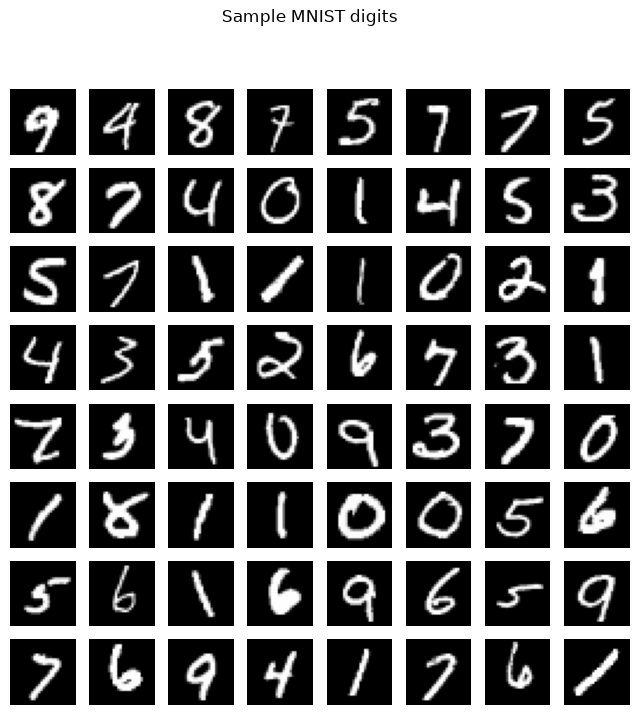

In [19]:
sample_batch, sample_labels = next(iter(train_loader)) #gives a sample batch
show_images(sample_batch, n=8, title="Sample MNIST digits")



## 2. Autoencoders (AE)

### Theory

An autoencoder is two networks glued together through a narrow middle:

- **Encoder** $f_\phi: \mathbb{R}^{784} \to \mathbb{R}^{k}$ compresses
  a flattened image $x$ into a latent code $z = f_\phi(x)$, where
  $k \ll 784$ — this bottleneck is the whole point.
- **Decoder** $g_\theta: \mathbb{R}^{k} \to \mathbb{R}^{784}$ maps
  $z$ back to a reconstruction $\hat{x} = g_\theta(z)$.

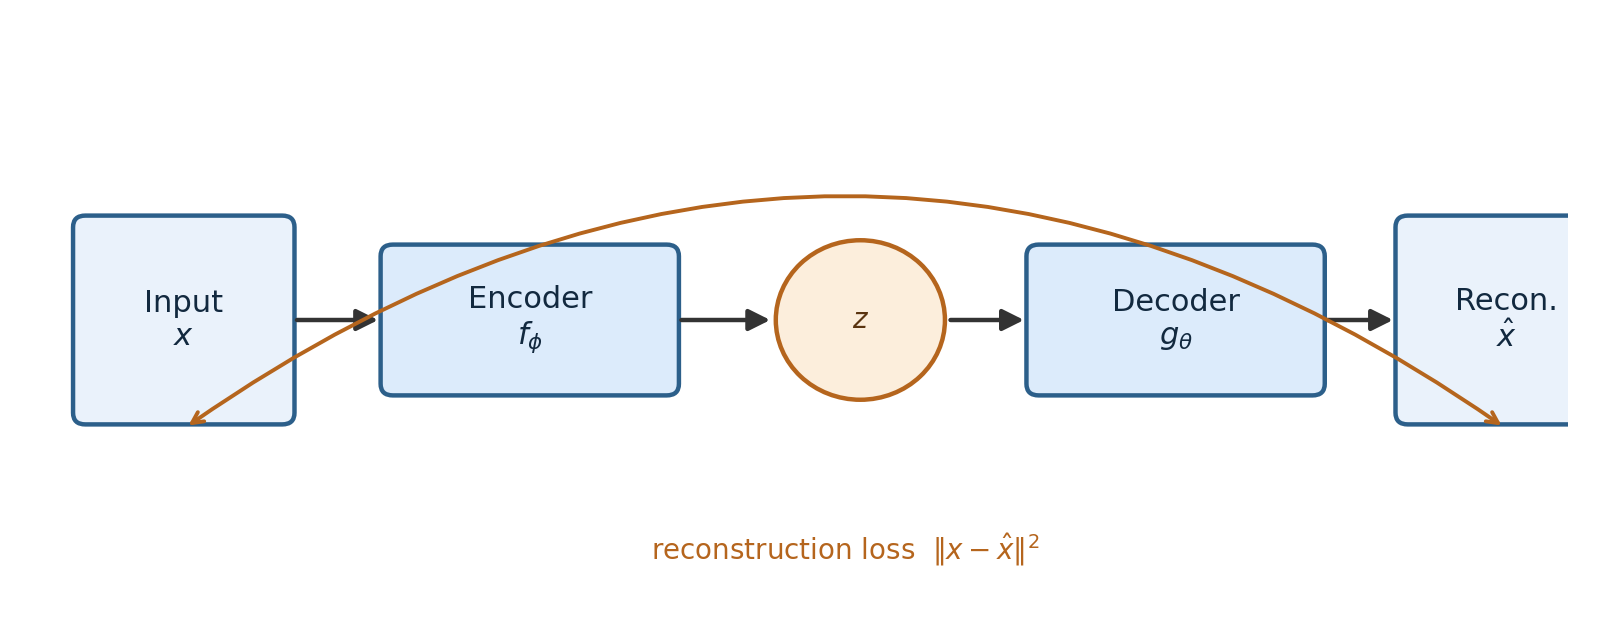

Training minimizes reconstruction error over the dataset:

$$
\mathcal{L}_{\text{AE}}(\theta, \phi) = \frac{1}{N}\sum_{i=1}^{N} \left\lVert x_i - g_\theta\big(f_\phi(x_i)\big) \right\rVert_2^2
$$

In practice, for pixel data in $[0,1]$, binary cross-entropy (treating each
pixel as a Bernoulli probability) trains just as well and is the more common
default — that's what you'll use below.

**Why the bottleneck matters:** if $z$ were as large as $x$, the network
could just copy the input straight through and learn nothing useful. Forcing
$z$ to be small means the network can only preserve the most important,
shared structure in the data.



### Your task: implement the `Encoder`

Build an `nn.Module` with:
- `nn.Linear(input_dim, hidden_dim)` → `ReLU`
- `nn.Linear(hidden_dim, latent_dim)`

`forward(x)` should return the latent code `z` (shape `(batch, latent_dim)`).
Assume `x` arrives already flattened to `(batch, input_dim)` — flattening
happens later, in the training loop.


In [24]:

class Encoder(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), #learning useful features before mapping to latent space
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim)
        )

    def forward(self, x):
        z = self.net(x)
        return z


To get latent data of an image:

```python

x_flat = x.view(x.size(0), -1).to(device)
z = ae.encoder(x_flat)          # skip the decoder entirely

```



### Your task: implement the `Decoder`

Build an `nn.Module` with:
- `nn.Linear(latent_dim, hidden_dim)` → `ReLU`
- `nn.Linear(hidden_dim, input_dim)` → `Sigmoid` (squashes output to `[0,1]`,
  matching our BCE loss and the pixel range)

`forward(z)` should return the reconstruction `x_hat` (shape
`(batch, input_dim)`).


In [28]:

class Decoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, hidden_dim=HIDDEN_DIM, output_dim=INPUT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),
            nn.Sigmoid()  # to ensure output is in [0, 1] range
        )

    def forward(self, x):
        z_hat = self.net(x)
        return z_hat # .view(-1, 28, 28),  -1 signifies automatic matching of the batch size, and we reshape to (batch_size, 28, 28) for image output



###  `Autoencoder`

Wire the encoder and decoder together. `forward(x)` should return
`x_hat` (the reconstruction).


In [29]:

class Autoencoder(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = Encoder(input_dim, hidden_dim, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim)

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat


In [ ]:

# Sanity check — shapes should match, and values should be in [0, 1]
ae = Autoencoder().to(device)
dummy_x = torch.rand(4, INPUT_DIM).to(device)   # 4 fake "images"
dummy_x_hat = ae(dummy_x)

assert dummy_x_hat.shape == dummy_x.shape, f"expected {dummy_x.shape}, got {dummy_x_hat.shape}"
assert dummy_x_hat.min() >= 0 and dummy_x_hat.max() <= 1, "decoder output should be in [0, 1] (check your Sigmoid)"
print("Autoencoder shapes and output range look correct.")

# expect (4, 728) here


Autoencoder shapes and output range look correct.



### Your task: write the AE training loop

Fill in the three missing pieces inside the loop below:
1. Flatten each image batch from `(batch, 1, 28, 28)` to `(batch, 784)` —
   use `.view(x.size(0), -1)`.
2. Compute the loss: run the batch through the model, then compute
   `F.binary_cross_entropy(x_hat, x, reduction='sum')`, and **divide by the
   batch size** so the loss is comparable across different batch sizes.
3. The three-line backprop + optimizer dance: zero the gradients, call
   `.backward()`, then `optimizer.step()`.

We've left `optimizer` creation in for you (it's boilerplate), but you write
everything inside the `for x, _ in train_loader:` loop.


![alt text](image.png)

In [32]:

ae = Autoencoder().to(device)
optimizer = torch.optim.Adam(ae.parameters(), lr=LR)

ae_train_losses = []

for epoch in range(EPOCHS):
    epoch_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        x = x.view(x.size(0), -1)

        z = ae(x)
        loss = F.binary_cross_entropy(z, x, reduction='sum') / x.size(0)  # compute BCE loss averaged over batch size

        optimizer.zero_grad() # stores model parameters
        loss.backward() # each iteration fresh graph
        # these 2 access grad

        optimizer.step()
        

        epoch_loss += loss.item() * x.size(0)

    epoch_loss /= len(train_dataset)
    ae_train_losses.append(epoch_loss)
    print(f"Epoch {epoch+1}/{EPOCHS} — AE loss: {epoch_loss:.2f}")


Epoch 1/15 — AE loss: 181.46
Epoch 2/15 — AE loss: 161.09
Epoch 3/15 — AE loss: 156.24
Epoch 4/15 — AE loss: 153.60
Epoch 5/15 — AE loss: 151.75
Epoch 6/15 — AE loss: 150.37
Epoch 7/15 — AE loss: 149.16
Epoch 8/15 — AE loss: 148.18
Epoch 9/15 — AE loss: 147.32
Epoch 10/15 — AE loss: 146.50
Epoch 11/15 — AE loss: 145.83
Epoch 12/15 — AE loss: 145.08
Epoch 13/15 — AE loss: 144.53
Epoch 14/15 — AE loss: 143.98
Epoch 15/15 — AE loss: 143.46



### Sanity check: is it actually learning?

Plot the training loss curve. It should drop quickly for the first few
epochs and then flatten out. If it's flat from epoch 1, something in your
training loop isn't updating the weights (check the TODO 3 lines).


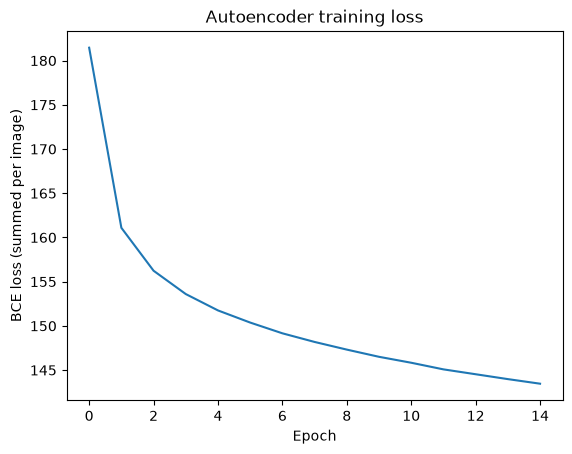

In [33]:

plt.plot(ae_train_losses)
plt.xlabel("Epoch")
plt.ylabel("BCE loss (summed per image)")
plt.title("Autoencoder training loss")
plt.show()



### Your task: visualize reconstructions

Take one batch from `test_loader`, run it through the trained `ae`, and use
your `show_images` helper to display the **originals on one row** and the
**reconstructions directly below them on a second row**. (Two calls to
`show_images` is fine — one per row.)

Remember: `ae` expects flattened input, and its output is also flattened —
your `show_images` function should already handle reshaping back to images.


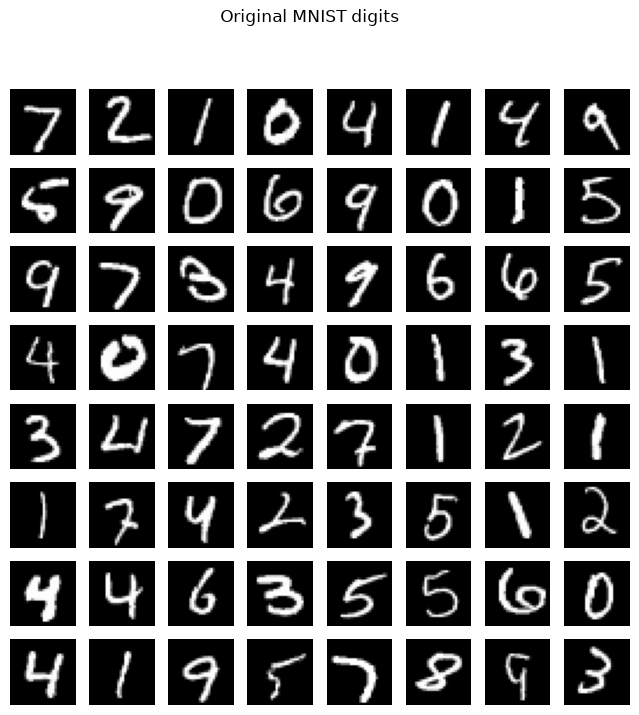

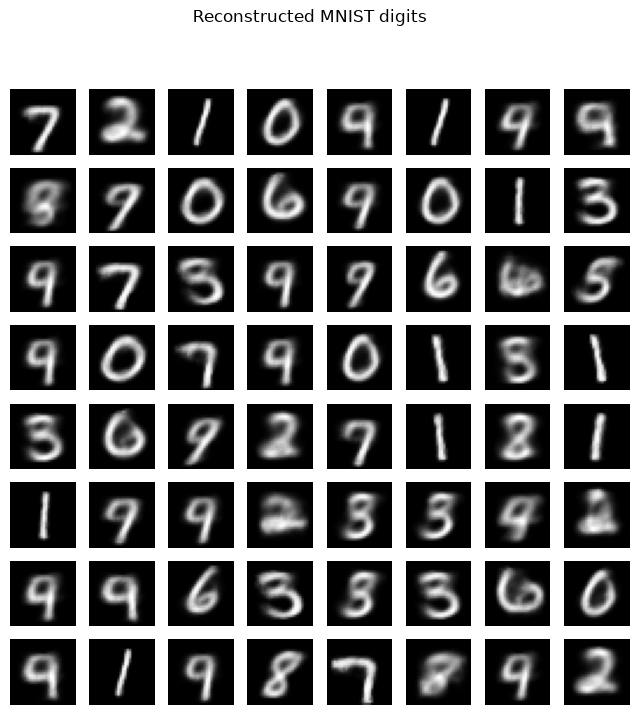

In [ ]:
images, labels = next(iter(test_loader))

ae.eval()

images = images.to(device)
images_flat = images.view(images.size(0), -1)

with torch.no_grad():
    output_images = ae(images_flat)


# detach needed because pytorch refuses to convert a tensor that's still tracking gradients into a NumPy array

show_images(images.detach().cpu().numpy(), n=8, title="Original MNIST digits")

show_images(output_images.detach().cpu().numpy(), n=8, title="Reconstructed MNIST digits")



## 3. Exploring the AE's latent space

Because we used `LATENT_DIM = 2`, we can plot every digit's latent code
directly as a point on a 2D scatter plot, colored by its true label. This is
one of the most informative things you can do with a small-latent-dim model.


1. Run the **encoder only** (not the full autoencoder) over the entire test
   set, collecting the 2D latent codes and their true labels.
2. Make a scatter plot: x-axis = first latent dimension, y-axis = second
   latent dimension, colored by digit label (`c=labels, cmap='tab10'`). Add
   a colorbar and axis labels.

**Hint:** loop over `test_loader`, call `ae.encoder(x_flat)`, and accumulate
results with `torch.cat` or plain Python lists + `np.concatenate` at the end.
Don't forget `.detach().cpu().numpy()` before plotting.


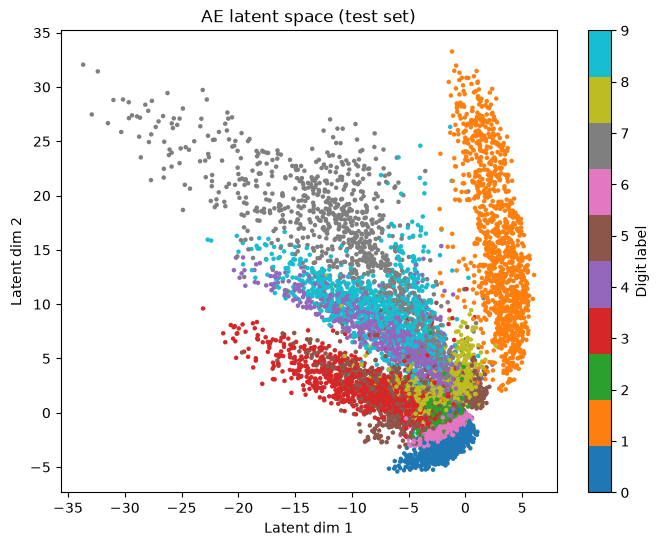

In [ ]:
# torch.cat and np.concatenate both stitch multiple tensors into one along an existing axis; as opposed to torch.stack / np.stack, which adds a new dimension

ae.eval()

all_latents = []
all_labels = []

for images, labels in test_loader:
    images = images.to(device)
    x_flat = images.view(images.size(0), -1)
    with torch.no_grad():
        latent_x = ae.encoder(x_flat)
    all_latents.append(latent_x.detach().cpu().numpy())
    all_labels.append(labels.numpy())

latents = np.concatenate(all_latents)
labels = np.concatenate(all_labels)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(latents[:, 0], latents[:, 1], c=labels, cmap='tab10', s=5) # scatter convenient for generating automatic legends
plt.colorbar(scatter, label="Digit label")
plt.xlabel("latent dim 1")
plt.ylabel("latent dim 2")
plt.title("AE latent space")
plt.show()



## 4. Variational Autoencoders (VAE)

### Theory: from a fixed code to a distribution

A VAE turns the autoencoder into a real generative model by making the
latent space **probabilistic**. Instead of the encoder outputting one fixed
point $z$, it outputs the parameters of a distribution — a mean $\mu(x)$ and
a log-variance $\log\sigma^2(x)$ — and $z$ is *sampled* from
$\mathcal{N}(\mu(x), \sigma(x)^2 I)$.

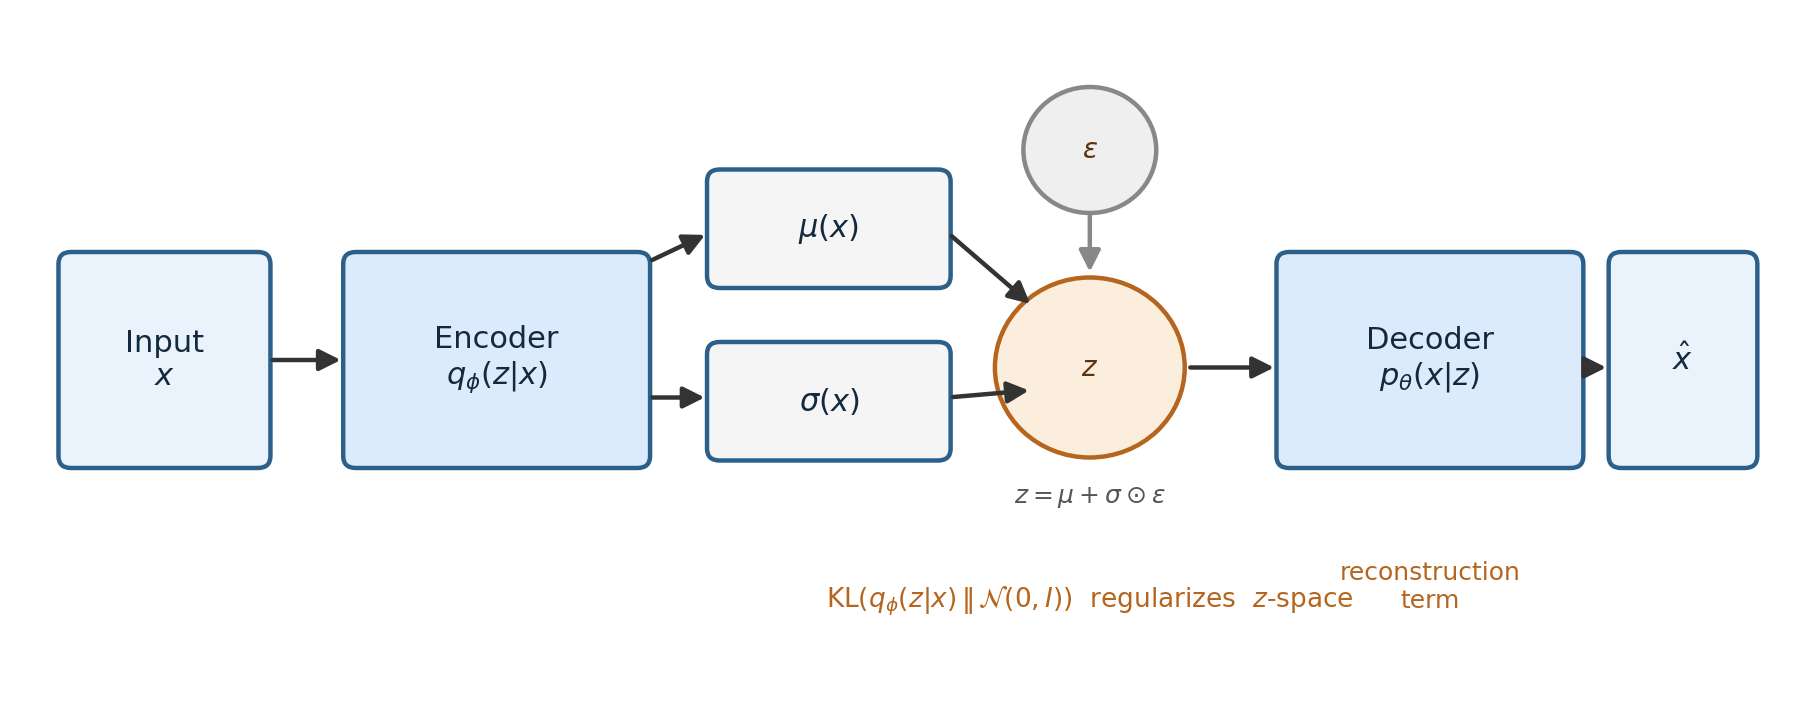

We also add a prior $p(z) = \mathcal{N}(0, I)$ and push the encoder's output
distribution toward that prior. The training objective (the **ELBO**, derived
from maximizing a lower bound on data likelihood.

$$
\mathcal{L}_{\text{VAE}} = \underbrace{-\,\mathbb{E}_{q_\phi(z\mid x)}\big[\log p_\theta(x\mid z)\big]}_{\text{reconstruction term}} \;+\; \underbrace{D_{KL}\big(q_\phi(z\mid x)\,\|\,p(z)\big)}_{\text{regularization term}}
$$

With a diagonal Gaussian $q_\phi(z\mid x) = \mathcal{N}(\mu, \operatorname{diag}(\sigma^2))$
and prior $\mathcal{N}(0, I)$, the KL term has a **closed form** — no
sampling or estimation needed:

$$
D_{KL} = \frac{1}{2}\sum_{j=1}^{k}\Big(\mu_j^2 + \sigma_j^2 - \log \sigma_j^2 - 1\Big)
$$

and if the reconstruction term uses BCE (as we did for the AE), the two
pieces together are exactly what you'll implement below.

### The reparameterization trick

Sampling $z \sim \mathcal{N}(\mu, \sigma^2)$ directly isn't differentiable
with respect to $\mu, \sigma$ — you can't backprop through a random sampling
op. The fix: sample noise $\epsilon \sim \mathcal{N}(0, I)$ separately, then
compute

$$
z = \mu + \sigma \odot \epsilon
$$

Now $z$ is a *deterministic, differentiable* function of $\mu$ and $\sigma$
(with the randomness pushed into $\epsilon$, which needs no gradient), so
ordinary backprop works.

**Why predict `logvar` instead of `sigma` directly?** Because `logvar` can be
any real number, while a variance must be positive — predicting the log
avoids the network ever needing to output a negative variance. Recover the
standard deviation with `std = torch.exp(0.5 * logvar)`.



### Your task: implement the `VAEEncoder`

Build an `nn.Module` with:
- A shared trunk: `nn.Linear(input_dim, hidden_dim)` → `ReLU`
- Two separate output heads from that shared hidden representation:
  `nn.Linear(hidden_dim, latent_dim)` for `mu`, and another
  `nn.Linear(hidden_dim, latent_dim)` for `logvar`

`forward(x)` should return **both** `mu` and `logvar` (two tensors, each of
shape `(batch, latent_dim)`).


In [60]:

class VAEEncoder(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()

        self.shared = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU()
        )

        self.mc_mu = nn.Sequential(
            nn.Linear(hidden_dim, latent_dim)
        )

        self.fc_logvar = nn.Sequential(
            nn.Linear(hidden_dim, latent_dim)
                )

    def forward(self, x):
        _x = self.shared(x)
        return self.mc_mu(_x), self.fc_logvar(_x)
    



### Your task: implement `reparameterize`

Write a standalone function implementing $z = \mu + \sigma \odot \epsilon$.

**Hint:** `std = torch.exp(0.5 * logvar)`, then draw `eps` the same shape as
`std` with `torch.randn_like(std)`.


In [61]:

def reparameterize(mu, logvar):
    std = torch.exp(0.5 * logvar)
    return mu + std * torch.randn_like(std)


In [62]:

# Sanity check — with logvar very negative (std ~ 0), z should land very close to mu
mu_test = torch.zeros(1000, 2)
logvar_test = torch.full((1000, 2), -10.0)
z_test = reparameterize(mu_test, logvar_test)

assert z_test.shape == mu_test.shape
# check that the shape is correct and sampled z lands close to the mean (within STD)
assert torch.allclose(z_test, mu_test, atol=1e-1), \
    "with near-zero std, z should be almost exactly mu — check your formula"
print("reparameterize looks correct.")


reparameterize looks correct.



### Your task: implement the `VAE`

Reuse the same `Decoder` class you already wrote for the AE (a decoder is a
decoder — nothing about it changes for a VAE). Wire together:
`VAEEncoder` → `reparameterize` → `Decoder`.

`forward(x)` should return **all three** of `x_hat`, `mu`, `logvar` (the loss
function needs `mu` and `logvar`, not just the reconstruction).


In [63]:
class VAE(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = VAEEncoder(input_dim, hidden_dim, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim)

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = reparameterize(mu, logvar)
        x_hat = self.decoder(z)
        return x_hat, mu, logvar


In [64]:

# Sanity check
vae = VAE().to(device)
dummy_x = torch.rand(4, INPUT_DIM).to(device)
x_hat, mu, logvar = vae(dummy_x)

assert x_hat.shape == dummy_x.shape
assert mu.shape == (4, LATENT_DIM)
assert logvar.shape == (4, LATENT_DIM)
print("VAE shapes look correct.")


VAE shapes look correct.



### Your task: implement the VAE loss function

Write `vae_loss(x_hat, x, mu, logvar)` returning a single scalar: the
reconstruction term **plus** the KL term, using the two formulas from the
theory box above. Both terms should be summed over all dimensions and then
**divided by the batch size** (same convention as the AE loss), so the two
terms are on a comparable scale and so the loss doesn't depend on batch size.

Return `recon_loss`, `kl_loss`, and their sum — you'll want to log the first
two separately (see the note below on why).


In [ ]:
# how do we determine these loss functions?

def vae_loss(x_hat, x, mu, logvar):
    batch_size = x.size(0)

    recon_loss = F.binary_cross_entropy(x_hat, x, reduction='sum') / batch_size

    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch_size

    total_loss = recon_loss + kl_loss
    return recon_loss, kl_loss, total_loss



> **Why log `recon_loss` and `kl_loss` separately, not just their sum?**
> A common failure mode called **posterior collapse** happens when the KL
> term dominates too early: the encoder gives up and just outputs the prior
> ($\mu \approx 0$, $\sigma \approx 1$) for every input, ignoring $x$
> entirely. The total loss can look fine even when this happens — you only
> notice by watching the KL term separately and seeing it collapse to near
> zero.



### Your task: write the VAE training loop

Very similar to the AE loop, with two differences: the forward pass returns
three things, and the loss function needs `mu` and `logvar` too. Track
`recon_loss` and `kl_loss` in separate lists (in addition to the total),
following the monitoring advice above.


In [72]:
vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=LR)

vae_recon_losses = []
vae_kl_losses = []

for epoch in range(EPOCHS):
    epoch_recon = 0.0
    epoch_kl = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        x_flat = x.view(x.size(0), -1)

        x_hat, mu, logvar = vae(x_flat)
        recon_loss, kl_loss, loss = vae_loss(x_hat, x_flat, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_recon += recon_loss.item() * x.size(0)
        epoch_kl += kl_loss.item() * x.size(0)

    epoch_recon /= len(train_dataset)
    epoch_kl /= len(train_dataset)
    vae_recon_losses.append(epoch_recon)
    vae_kl_losses.append(epoch_kl)
    print(f"Epoch {epoch+1}/{EPOCHS} — recon: {epoch_recon:.2f}, KL: {epoch_kl:.2f}")


Epoch 1/15 — recon: 183.86, KL: 5.57
Epoch 2/15 — recon: 162.19, KL: 5.09
Epoch 3/15 — recon: 158.11, KL: 5.25
Epoch 4/15 — recon: 155.78, KL: 5.36
Epoch 5/15 — recon: 154.08, KL: 5.46
Epoch 6/15 — recon: 152.59, KL: 5.54
Epoch 7/15 — recon: 151.30, KL: 5.60
Epoch 8/15 — recon: 150.15, KL: 5.68
Epoch 9/15 — recon: 149.20, KL: 5.75
Epoch 10/15 — recon: 148.34, KL: 5.78
Epoch 11/15 — recon: 147.70, KL: 5.82
Epoch 12/15 — recon: 147.09, KL: 5.86
Epoch 13/15 — recon: 146.49, KL: 5.87
Epoch 14/15 — recon: 146.04, KL: 5.92
Epoch 15/15 — recon: 145.65, KL: 5.95



### Sanity check: plot both loss terms

Plot `vae_recon_losses` and `vae_kl_losses` as two separate lines on the same
axes (with a legend). Reconstruction loss should fall steadily; KL loss
typically rises a bit from its starting point before leveling off, as the
encoder starts actually using its latent space instead of ignoring it. If KL
crashes to ~0 and stays there, that's posterior collapse — see the note
above.


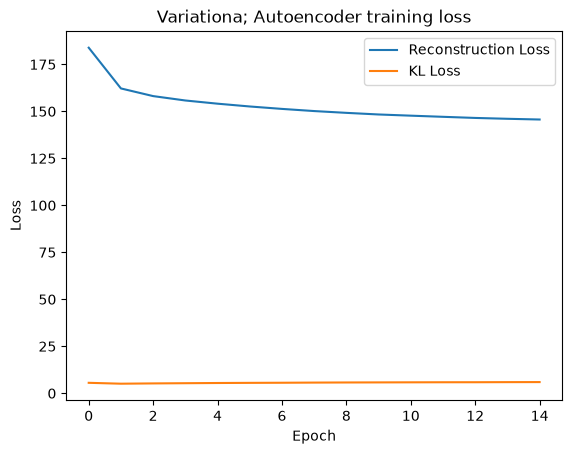

In [73]:

# TODO: plot vae_recon_losses and vae_kl_losses on one figure, with a legend

plt.plot(vae_recon_losses, label ="Reconstruction Loss" )
plt.plot(vae_kl_losses, label = "KL Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Variationa; Autoencoder training loss")
plt.show()



### Your task: visualize VAE reconstructions

Same as you did for the AE: take a test batch, reconstruct it through `vae`
(remember `forward` now returns three things — you only need `x_hat` here),
and display originals vs. reconstructions.


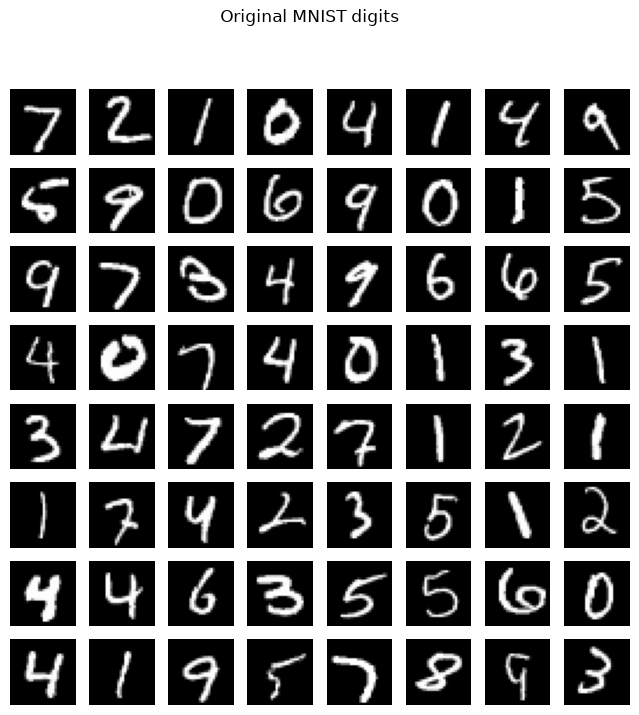

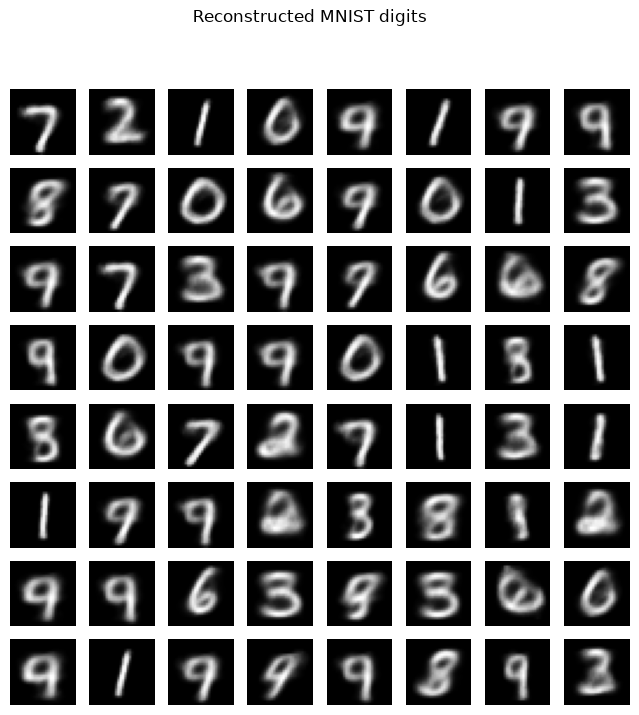

In [76]:
images, labels = next(iter(test_loader))

vae.eval()

images = images.to(device)
images_flat = images.view(images.size(0), -1)

with torch.no_grad():
    output_images, mu, logvar = vae(images_flat)


# detach needed because pytorch refuses to convert a tensor that's still tracking gradients into a NumPy array

show_images(images.detach().cpu().numpy(), n=8, title="Original MNIST digits")

show_images(output_images.detach().cpu().numpy(), n=8, title="Reconstructed MNIST digits")


Is this fixable with alpha beta weights for KL and Reconstruction terms? 


## 5. Generating new digits

This is the part a plain autoencoder can't principledly do: sample a random
point directly from the prior and decode it into a plausible new image.

### Your task

1. Sample `z ~ N(0, I)` of shape `(8, LATENT_DIM)` using `torch.randn`.
2. Pass it through `vae.decoder` (the decoder alone — no encoder involved,
   there's no input image here).
3. Display the results with `show_images`.


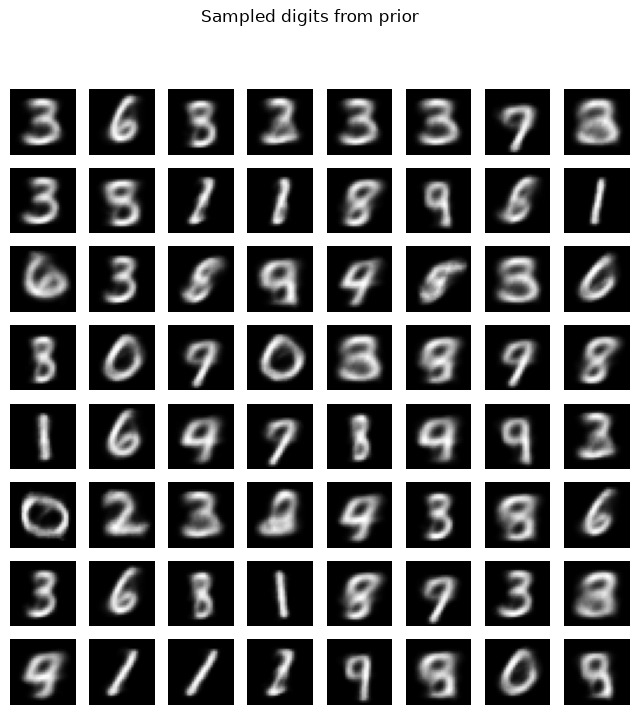

In [80]:


vae.eval()
z = torch.randn(64, LATENT_DIM).to(device)

with torch.no_grad():
    samples = vae.decoder(z)

show_images(samples.detach().cpu().numpy(), title="Sampled digits from prior")



### Your task: the VAE's latent space

Repeat the same latent-space scatter plot you made for the AE in Section 3,
but using `vae.encoder`'s `mu` output this time (use the mean, not a random
sample, so the plot reflects where each digit is *centered* in latent
space).

Compare the two scatter plots side by side (visually, or literally with
`plt.subplot(1, 2, ...)` if you want one figure). Look specifically at
whether the space between clusters looks "filled in" versus the AE's plot.


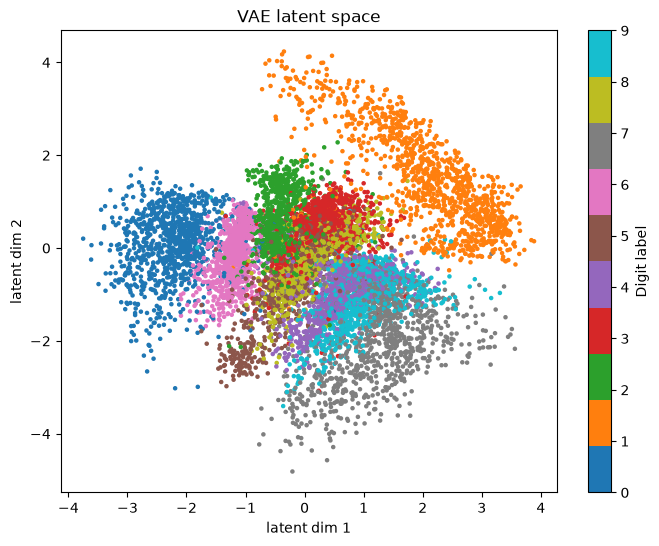

In [87]:
vae.eval()

all_latents = []
all_labels = []

for images, labels in test_loader:
    images = images.to(device)
    x_flat = images.view(images.size(0), -1)
    with torch.no_grad():
        latent_x, _ = vae.encoder(x_flat)
    all_latents.append(latent_x.detach().cpu().numpy())
    all_labels.append(labels.numpy())

latents = np.concatenate(all_latents)
labels = np.concatenate(all_labels)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(latents[:, 0], latents[:, 1], c=labels, cmap='tab10', s=5) # scatter convenient for generating automatic legends
plt.colorbar(scatter, label="Digit label")
plt.xlabel("latent dim 1")
plt.ylabel("latent dim 2")
plt.title("VAE latent space")
plt.show()




### Your task (bonus): latent space interpolation

Pick two test images of *different* digits. Encode both to get their `mu`
vectors ($z_a$ and $z_b$). Create 8 intermediate points by linearly
interpolating between them:
$z_t = (1-t)\, z_a + t\, z_b$ for $t \in \{0, 1/7, 2/7, \dots, 1\}$.
Decode all 8 and display them in a row with `show_images`.

If your VAE's latent space is well-organized, you should see one digit
morph smoothly into the other. Try the same experiment with the **AE**'s
latent space (interpolating between its encoder outputs instead) — the
transition is typically much less smooth, and may even pass through
garbage-looking images partway through. This is the practical payoff of the
KL term: it's what makes the space smoothly interpolatable in the first
place.


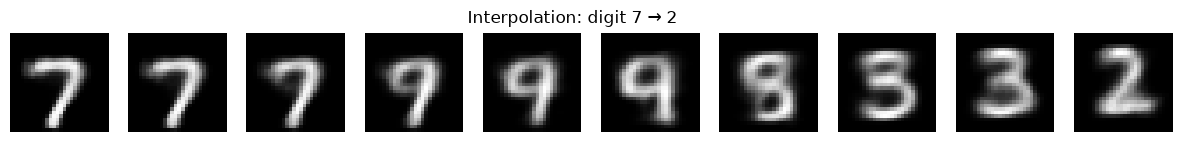

In [89]:
# TODO (bonus): interpolate between two digits in VAE latent space and decode the path

vae.eval()

images, labels = next(iter(test_loader))
images = images.to(device)
labels = labels.to(device)
images_flat = images.view(images.size(0), -1)

idx_a = 0
idx_b = (labels != labels[idx_a]).nonzero(as_tuple=True)[0][0].item()

with torch.no_grad():
    mu, _ = vae.encoder(images_flat)

z_a = mu[idx_a]
z_b = mu[idx_b]

n_steps = 10
alphas = torch.linspace(0, 1, n_steps, device=device)
z_interp = torch.stack([(1 - a) * z_a + a * z_b for a in alphas])

with torch.no_grad():
    decoded = vae.decoder(z_interp)

decoded = decoded.detach().cpu().numpy()

fig, axes = plt.subplots(1, n_steps, figsize=(n_steps * 1.5, 1.5))
for i, ax in enumerate(axes):
    ax.imshow(decoded[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
fig.suptitle(f"Interpolation: digit {labels[idx_a].item()} → {labels[idx_b].item()}")
plt.show()



## 6. Where to go from here

If everything above is working, you've implemented both models end to end.
A few directions to extend this notebook on your own:

- **Bigger latent space.** Set `LATENT_DIM = 20` (or more) and retrain both
  models. Reconstructions should get noticeably sharper. You'll lose the
  ability to scatter-plot the latent space directly — that's the classic
  trade-off of using a small latent dimension purely for visualization.
- **KL annealing / β-VAE.** Multiply the KL term in `vae_loss` by a weight
  `beta`. Ramp `beta` from 0 to 1 over the first several epochs (this is
  the standard fix for posterior collapse on harder datasets). Try
  `beta > 1` afterward and see how reconstruction sharpness trades off
  against how "organized" the latent scatter plot looks.
- **Convolutional encoder/decoder.** Swap the `nn.Linear` layers for
  `nn.Conv2d` / `nn.ConvTranspose2d` layers operating on `(1, 28, 28)`
  images directly instead of flattened vectors. This is the standard
  architecture for anything beyond MNIST-scale images.
- **Denoising AE.** Add Gaussian noise to the *input* of the autoencoder
  (but not to the reconstruction target), and see how it affects the
  learned latent space and robustness.

Nice work — you now have working, from-scratch implementations of both
models to build on.
